In [1]:
import os, sys, json, time, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import roc_auc_score, roc_curve

try:
    import timm
except ImportError:
    os.system("pip install -q --no-deps timm huggingface_hub safetensors")
    import timm

REPO_URL = "https://github.com/Mugdha-Naik/deepfake-detector-project.git"
REPO_DIR = "/kaggle/working/repo"
if not os.path.exists(REPO_DIR):
    os.system(f"git clone {REPO_URL} {REPO_DIR}")
else:
    os.system(f"cd {REPO_DIR} && git pull")
sys.path.append(REPO_DIR)
import dfx_model, dfx_data

INPUT_ROOT = "/kaggle/input"
OUT = "/kaggle/working/p2_5"
os.makedirs(OUT, exist_ok=True)

BATCH_SIZE, NUM_WORKERS = 64, 2
BOOT_REPS, BOOT_SEED = 1000, 2026
BLUR_BASELINE = True

def find_one(name, roots):
    for root in roots:
        matches = [os.path.join(d, name) for d, _, fs in os.walk(root) if name in fs]
        if len(matches) == 1:
            return matches[0]
        if len(matches) > 1:
            raise RuntimeError(f"{name}: {len(matches)} copies under {root}. Attach only one:\n" + "\n".join(matches))
    raise FileNotFoundError(f"{name} not found under {roots}")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "Set the Accelerator to GPU T4."
print("device:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| timm", timm.__version__)

Cloning into '/kaggle/working/repo'...


device: Tesla T4 | torch 2.11.0+cu128 | timm 1.0.29


In [2]:
# ============================================================
# LOAD THE TRAINED MODEL AND THE FROZEN THRESHOLD
# ============================================================
best_pt = find_one("best.pt", [INPUT_ROOT])
config_json = find_one("config.json", [INPUT_ROOT])
thr_json = find_one("threshold.json", [INPUT_ROOT])
config = json.load(open(config_json))
thr_info = json.load(open(thr_json))

assert not config.get("debug"), "config.json comes from a DEBUG run. Re-run p2_4_train.ipynb with DEBUG_SUBSET = None."
assert config["train_faces"] > 5000, f"train_faces = {config['train_faces']}: this is not the full training run"
THRESHOLD = float(thr_info["value"])
assert 0.0 < THRESHOLD < 1.0, f"suspicious threshold {THRESHOLD}"
MEAN, STD, SIZE = tuple(config["mean"]), tuple(config["std"]), dfx_model.INPUT_SIZE

manifest_csv = find_one("faces_manifest.csv", [INPUT_ROOT, REPO_DIR])
meta = json.load(open(find_one("manifest_meta.json", [INPUT_ROOT, REPO_DIR])))
assert sha256(manifest_csv) == meta["manifest_sha256"], "faces_manifest.csv does not match manifest_meta.json"
assert config["manifest_sha256"] == meta["manifest_sha256"], "the model was trained on a different manifest than the one attached now"

model, info = dfx_model.build_xception(pretrained=False)
dfx_model.load_checkpoint(model, best_pt, map_location=device)
model = model.to(device).eval()
print(f"model: {best_pt}\n  best epoch {config['best_epoch']} | best val AUC {config['best_val_auc']:.4f}")
print(f"FROZEN threshold: {THRESHOLD:.4f} ({thr_info['method']}) | val face AUC {thr_info['val_face_auc']:.4f} | val video AUC {thr_info['val_video_auc']:.4f}")
print("manifest sha256 verified:", meta["manifest_sha256"][:8])

model: /kaggle/input/notebooks/mugdhanaik/phase2-3-4-debugsubsetisnone/p2_train/best.pt
  best epoch 8 | best val AUC 0.9735
FROZEN threshold: 0.2217 (youden_j_on_val) | val face AUC 0.9735 | val video AUC 0.9922
manifest sha256 verified: 80eae250


In [3]:
# ============================================================
# BUILD THE FOUR CONDITION TABLES (A, B, C, D) AND LOCATE THEIR CROPS
# ============================================================
m = pd.read_csv(manifest_csv)
print("roles in manifest:", m["role"].value_counts().to_dict())

assert {"test_A", "test_C"} <= set(m["role"]), "expected roles test_A and test_C"
CLEAN_ROOT = dfx_data.resolve_dir("step5_faces", INPUT_ROOT)

cond = {}
cond["A"] = {"df": m[m["role"] == "test_A"].reset_index(drop=True), "root": CLEAN_ROOT, "name": "A: FF++ test (clean)"}
cond["C"] = {"df": m[m["role"] == "test_C"].reset_index(drop=True), "root": CLEAN_ROOT, "name": "C: Celeb-DF test (clean)"}

def locate_compressed(df, letter):
    """Find which column of the B/D manifest holds the crop path, and which directory it is relative to."""
    cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]) and str(df[c].iloc[0]).lower().endswith((".jpg", ".jpeg", ".png"))]
    assert cols, f"manifest {letter}: no column that looks like an image path. Columns: {list(df.columns)}"
    cands = set()
    for d, subdirs, _ in os.walk(INPUT_ROOT):
        if os.path.basename(d) in ("compressed_faces", f"faces_{letter}", "conditions"):
            cands.add(d); cands.add(os.path.dirname(d))
        for s in subdirs:
            if s in (f"faces_{letter}", "compressed_faces"):
                cands.add(d)
    sample = df.sample(min(8, len(df)), random_state=0)
    for col in cols:
        for root in sorted(cands):
            for tf in (lambda r: r, lambda r: os.path.basename(str(r).replace("\\", "/")),
                       lambda r: f"faces_{letter}/" + os.path.basename(str(r).replace("\\", "/"))):
                if all(os.path.exists(os.path.join(root, tf(r))) for r in sample[col]):
                    return col, root, tf
    raise FileNotFoundError(f"could not find the crops of condition {letter}. Candidate roots: {sorted(cands)}; columns tried: {cols}")

for letter, clean_letter, label in [("B", "A", "B: FF++ test (compressed)"), ("D", "C", "D: Celeb-DF test (compressed)")]:
    p = find_one(f"faces_manifest_{letter}.csv", [INPUT_ROOT, REPO_DIR])
    d = pd.read_csv(p)
    print(f"\nmanifest {letter}: {p} | rows {len(d)} | columns {list(d.columns)}")
    clean = cond[clean_letter]["df"]
    # fill label / video_id from the clean twin if the compressed manifest does not carry them
    if "pair_id" in d.columns and set(d["pair_id"]) <= set(m["face_id"]):
        twin = m.set_index("face_id")
        for c in ("label", "video_id", "label_name"):
            if c not in d.columns and c in twin.columns:
                d[c] = d["pair_id"].map(twin[c])
    need = ["face_id", "video_id", "label"]
    assert all(c in d.columns for c in need), f"manifest {letter} lacks {[c for c in need if c not in d.columns]}"
    col, root, tf = locate_compressed(d, letter)
    d["face_rel"] = d[col].map(tf)
    print(f"  crops: column '{col}' under {root}")
    cond[letter] = {"df": d.reset_index(drop=True), "root": root, "name": label}

expected = {"A": (5883, 198), "B": (5883, 198), "C": (8763, 300), "D": (8763, 300)}
rows = []
for k, v in cond.items():
    df = v["df"]
    assert df["face_id"].is_unique, f"{k}: face_id not unique"
    missing = [r for r in df["face_rel"] if not os.path.exists(os.path.join(v["root"], r))]
    assert not missing, f"{k}: {len(missing)} crops missing, e.g. {missing[:2]}"
    rows.append({"cond": k, "faces": len(df), "videos": df["video_id"].nunique(), "REAL": int((df["label"] == 0).sum()), "FAKE": int((df["label"] == 1).sum()),
                 "expected": expected[k]})
cs = pd.DataFrame(rows); print("\n", cs.to_string(index=False))
for k, (nf, nv) in expected.items():
    if (len(cond[k]["df"]), cond[k]["df"]["video_id"].nunique()) != (nf, nv):
        print(f"WARNING: condition {k} has {len(cond[k]['df'])} faces / {cond[k]['df']['video_id'].nunique()} videos, expected {nf} / {nv}")
assert set(cond["A"]["df"]["video_id"]) == set(cond["B"]["df"]["video_id"]), "A and B must contain the same videos"
assert set(cond["C"]["df"]["video_id"]) == set(cond["D"]["df"]["video_id"]), "C and D must contain the same videos"

roles in manifest: {'train': 11741, 'test_C': 8763, 'test_A': 5883, 'val': 1797}

manifest B: /kaggle/input/notebooks/mugdhanaik/phase2-step2/faces_manifest_B.csv | rows 5883 | columns ['face_id', 'pair_id', 'face_rel', 'video_id', 'video_key', 'video_path', 'dataset', 'method', 'label_name', 'label', 'split', 'role', 'condition', 'frame_number', 'x1', 'y1', 'x2', 'y2', 'face_width', 'face_height', 'blur_lapvar', 'crf', 'preset']
  crops: column 'face_rel' under /kaggle/input/notebooks/mugdhanaik/phase2-step2/compressed_faces

manifest D: /kaggle/input/notebooks/mugdhanaik/phase2-step2/faces_manifest_D.csv | rows 8763 | columns ['face_id', 'pair_id', 'face_rel', 'video_id', 'video_key', 'video_path', 'dataset', 'method', 'label_name', 'label', 'split', 'role', 'condition', 'frame_number', 'x1', 'y1', 'x2', 'y2', 'face_width', 'face_height', 'blur_lapvar', 'crf', 'preset']
  crops: column 'face_rel' under /kaggle/input/notebooks/mugdhanaik/phase2-step2/compressed_faces

 cond  faces  vi

In [4]:
# ============================================================
# PREDICT (frozen model, frozen threshold) AND TAG TP / FP / FN / TN
# ============================================================
@torch.no_grad()
def predict(df, root):
    loader = dfx_data.make_loader(df, root, MEAN, STD, SIZE, train=False, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    ids, probs = [], []
    for x, y, fid in loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logit = model(x.to(device, non_blocking=True)).squeeze(1)
        probs.append(torch.sigmoid(logit.float()).cpu().numpy()); ids += list(fid)
    return pd.DataFrame({"face_id": ids, "prob_fake": np.concatenate(probs)})

def outcome(label, pred):
    return np.where(label == 1, np.where(pred == 1, "TP", "FN"), np.where(pred == 1, "FP", "TN"))

preds, vids_tab = {}, {}
t0 = time.time()
for k in "ABCD":
    df, root = cond[k]["df"], cond[k]["root"]
    p = predict(df, root)
    assert len(p) == len(df) and p["face_id"].is_unique and set(p["face_id"]) == set(df["face_id"]), f"{k}: predictions do not match the manifest rows"
    keep = [c for c in ["face_id", "video_id", "label", "label_name", "pair_id"] if c in df.columns]
    out = df[keep].merge(p, on="face_id", how="left")
    out["pred"] = (out["prob_fake"] >= THRESHOLD).astype(int)
    out["outcome"] = outcome(out["label"].to_numpy(), out["pred"].to_numpy())
    out.to_csv(os.path.join(OUT, f"predictions_{k}.csv"), index=False)
    v = out.groupby("video_id").agg(label=("label", "first"), prob_fake=("prob_fake", "mean"), n_faces=("face_id", "size"),
                                    frac_faces_fake=("pred", "mean")).reset_index()
    v["pred"] = (v["prob_fake"] >= THRESHOLD).astype(int)
    v["outcome"] = outcome(v["label"].to_numpy(), v["pred"].to_numpy())
    v.to_csv(os.path.join(OUT, f"video_predictions_{k}.csv"), index=False)
    preds[k], vids_tab[k] = out, v
    print(f"{k}: {len(out)} faces | {len(v)} videos | face outcomes {out['outcome'].value_counts().to_dict()} | {time.time() - t0:.0f}s")

A: 5883 faces | 198 videos | face outcomes {'TN': 2566, 'TP': 2368, 'FN': 632, 'FP': 317} | 232s
B: 5883 faces | 198 videos | face outcomes {'TN': 2697, 'FN': 2595, 'TP': 405, 'FP': 186} | 451s
C: 8763 faces | 300 videos | face outcomes {'TP': 3605, 'FP': 2321, 'TN': 2060, 'FN': 777} | 787s
D: 8763 faces | 300 videos | face outcomes {'TN': 3572, 'FN': 3243, 'TP': 1139, 'FP': 809} | 1114s


In [5]:
# ============================================================
# METRICS WITH VIDEO-LEVEL BOOTSTRAP CIs
# ============================================================
METRICS = ["auc", "acc", "precision", "recall", "specificity", "f1", "bal_acc"]

def metrics_from(y, p, thr):
    y = np.asarray(y).astype(int); p = np.asarray(p, dtype=float)
    pred = p >= thr
    tp = int(((y == 1) & pred).sum()); fn = int(((y == 1) & ~pred).sum())
    fp = int(((y == 0) & pred).sum()); tn = int(((y == 0) & ~pred).sum())
    rec = tp / (tp + fn) if tp + fn else np.nan
    spec = tn / (tn + fp) if tn + fp else np.nan
    prec = tp / (tp + fp) if tp + fp else np.nan
    f1 = 2 * prec * rec / (prec + rec) if (prec == prec and rec == rec and prec + rec > 0) else np.nan
    auc = float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else np.nan
    return {"auc": auc, "acc": (tp + tn) / len(y), "precision": prec, "recall": rec, "specificity": spec, "f1": f1,
            "bal_acc": np.nanmean([rec, spec]), "tp": tp, "fp": fp, "fn": fn, "tn": tn}

def bootstrap(face_df, thr, reps, seed):
    """Resample VIDEOS with replacement. Same seed + same sorted video list => identical draws (used for paired deltas)."""
    face_df = face_df.sort_values(["video_id", "face_id"]).reset_index(drop=True)
    groups = face_df.groupby("video_id", sort=True).indices
    vids = sorted(groups)
    gi = [groups[v] for v in vids]
    y, p = face_df["label"].to_numpy(), face_df["prob_fake"].to_numpy()
    vy = np.array([y[g[0]] for g in gi]); vp = np.array([p[g].mean() for g in gi])
    draws = np.random.default_rng(seed).integers(0, len(vids), size=(reps, len(vids)))
    rec_f, rec_v = [], []
    for r in range(reps):
        sel = draws[r]
        fi = np.concatenate([gi[s] for s in sel])
        rec_f.append({k: v for k, v in metrics_from(y[fi], p[fi], thr).items() if k in METRICS})
        rec_v.append({k: v for k, v in metrics_from(vy[sel], vp[sel], thr).items() if k in METRICS})
    return pd.DataFrame(rec_f), pd.DataFrame(rec_v)

def ci(a):
    a = np.asarray(a, dtype=float)
    return (float(np.nanpercentile(a, 2.5)), float(np.nanpercentile(a, 97.5))) if np.isfinite(a).any() else (np.nan, np.nan)

boots, long_rows = {}, []
t0 = time.time()
for k in "ABCD":
    f, v = preds[k], vids_tab[k]
    point = {"face": metrics_from(f["label"], f["prob_fake"], THRESHOLD), "video": metrics_from(v["label"], v["prob_fake"], THRESHOLD)}
    bf, bv = bootstrap(f, THRESHOLD, BOOT_REPS, BOOT_SEED + (0 if k in "AB" else 1))
    boots[k] = {"face": bf, "video": bv}
    for level, b in (("face", bf), ("video", bv)):
        n = len(f) if level == "face" else len(v)
        for met in METRICS:
            lo, hi = ci(b[met])
            long_rows.append({"cond": k, "level": level, "n": n, "metric": met, "value": point[level][met], "ci_lo": lo, "ci_hi": hi})
        for c in ("tp", "fp", "fn", "tn"):
            long_rows.append({"cond": k, "level": level, "n": n, "metric": c, "value": point[level][c], "ci_lo": np.nan, "ci_hi": np.nan})
    print(f"bootstrap {k} done ({time.time() - t0:.0f}s)")

long = pd.DataFrame(long_rows)
long.to_csv(os.path.join(OUT, "metrics_long.csv"), index=False)

def fmt(r):
    return f"{r.value:.3f} [{r.ci_lo:.3f}, {r.ci_hi:.3f}]"
for level in ("face", "video"):
    t = long[(long["level"] == level) & long["metric"].isin(METRICS)].copy()
    t["txt"] = t.apply(fmt, axis=1)
    wide = t.pivot(index="cond", columns="metric", values="txt")[METRICS]
    wide.to_csv(os.path.join(OUT, f"metrics_{level}.csv"))
    print(f"\n=== {level.upper()}-LEVEL metrics at threshold {THRESHOLD:.4f} (95% CI, videos resampled, {BOOT_REPS} reps) ===")
    print(wide.to_string())

bootstrap A done (4s)
bootstrap B done (7s)
bootstrap C done (12s)
bootstrap D done (16s)

=== FACE-LEVEL metrics at threshold 0.2217 (95% CI, videos resampled, 1000 reps) ===
metric                   auc                   acc             precision                recall           specificity                    f1               bal_acc
cond                                                                                                                                                            
A       0.917 [0.882, 0.946]  0.839 [0.804, 0.873]  0.882 [0.833, 0.926]  0.789 [0.732, 0.843]  0.890 [0.850, 0.929]  0.833 [0.792, 0.870]  0.840 [0.806, 0.873]
B       0.611 [0.556, 0.666]  0.527 [0.465, 0.589]  0.685 [0.573, 0.790]  0.135 [0.102, 0.170]  0.935 [0.912, 0.955]  0.226 [0.176, 0.278]  0.535 [0.516, 0.556]
C       0.704 [0.661, 0.746]  0.646 [0.608, 0.684]  0.608 [0.549, 0.668]  0.823 [0.789, 0.857]  0.470 [0.410, 0.525]  0.699 [0.657, 0.743]  0.646 [0.614, 0.676]
D       0.577 [0.53

In [6]:
# ============================================================
# EFFECT OF SHIFT: paired deltas (A->B, C->D share the same video draws) and independent (A->C)
# ============================================================
DELTA_METRICS = ["auc", "acc", "recall", "specificity", "f1"]
d_rows = []
for a, b, kind in [("A", "B", "compression (paired)"), ("C", "D", "compression (paired)"), ("A", "C", "dataset shift (independent)")]:
    for level in ("face", "video"):
        xa, xb = boots[a][level], boots[b][level]   # A,B and C,D were bootstrapped with identical video draws (paired)
        pa = long[(long.cond == a) & (long.level == level)].set_index("metric")["value"]
        pb = long[(long.cond == b) & (long.level == level)].set_index("metric")["value"]
        for met in DELTA_METRICS:
            diff = xb[met].to_numpy() - xa[met].to_numpy()
            lo, hi = ci(diff)
            d_rows.append({"change": f"{a} -> {b}", "kind": kind, "level": level, "metric": met, "from": pa[met], "to": pb[met],
                           "delta": pb[met] - pa[met], "ci_lo": lo, "ci_hi": hi, "ci_excludes_0": bool(lo > 0 or hi < 0)})
deltas = pd.DataFrame(d_rows)
deltas.to_csv(os.path.join(OUT, "metric_deltas.csv"), index=False)
print(deltas[deltas["level"] == "face"].round(4).to_string(index=False))

# ---- prediction flips between clean and compressed twins (needed by Step 2.8) ----
def twin_key(comp, clean):
    if "pair_id" in comp.columns and set(comp["pair_id"]) <= set(clean["face_id"]):
        return comp["pair_id"]
    if set(comp["face_id"]) <= set(clean["face_id"]):
        return comp["face_id"]
    return None

flip_rows = []
for clean_k, comp_k in [("A", "B"), ("C", "D")]:
    c, d = preds[clean_k], preds[comp_k].copy()
    key = twin_key(d, c)
    if key is None:
        print(f"{comp_k}: cannot pair with {clean_k} (no pair_id or matching face_id): flip table skipped"); continue
    d["pair_key"] = key.to_numpy()
    j = d.merge(c[["face_id", "prob_fake", "pred", "outcome"]].rename(columns={"face_id": "pair_key", "prob_fake": "prob_clean", "pred": "pred_clean", "outcome": "outcome_clean"}), on="pair_key", how="inner")
    j = j.rename(columns={"prob_fake": "prob_comp", "pred": "pred_comp", "outcome": "outcome_comp"})
    j["flipped"] = j["pred_clean"] != j["pred_comp"]
    j["abs_prob_change"] = (j["prob_comp"] - j["prob_clean"]).abs()
    j[["pair_key", "face_id", "video_id", "label", "prob_clean", "prob_comp", "pred_clean", "pred_comp", "outcome_clean", "outcome_comp", "flipped", "abs_prob_change"]].to_csv(
        os.path.join(OUT, f"flips_{clean_k}_{comp_k}.csv"), index=False)
    ok_c, ok_d = j["pred_clean"] == j["label"], j["pred_comp"] == j["label"]
    flip_rows.append({"pair": f"{clean_k}->{comp_k}", "twins": len(j), "flipped %": round(100 * j["flipped"].mean(), 2),
                      "correct->wrong": int((ok_c & ~ok_d).sum()), "wrong->correct": int((~ok_c & ok_d).sum()),
                      "REAL->FAKE flips": int(((j.pred_clean == 0) & (j.pred_comp == 1)).sum()),
                      "FAKE->REAL flips": int(((j.pred_clean == 1) & (j.pred_comp == 0)).sum()),
                      "mean |dP|": round(j["abs_prob_change"].mean(), 4)})
flips = pd.DataFrame(flip_rows); flips.to_csv(os.path.join(OUT, "flip_summary.csv"), index=False)
print("\n", flips.to_string(index=False))

change                        kind level      metric   from     to   delta   ci_lo   ci_hi  ci_excludes_0
A -> B        compression (paired)  face         auc 0.9168 0.6109 -0.3060 -0.3587 -0.2503           True
A -> B        compression (paired)  face         acc 0.8387 0.5273 -0.3114 -0.3782 -0.2543           True
A -> B        compression (paired)  face      recall 0.7893 0.1350 -0.6543 -0.7113 -0.5953           True
A -> B        compression (paired)  face specificity 0.8900 0.9355  0.0454  0.0061  0.0865           True
A -> B        compression (paired)  face          f1 0.8331 0.2256 -0.6075 -0.6640 -0.5477           True
C -> D        compression (paired)  face         auc 0.7045 0.5766 -0.1279 -0.1752 -0.0823           True
C -> D        compression (paired)  face         acc 0.6465 0.5376 -0.1089 -0.1685 -0.0483           True
C -> D        compression (paired)  face      recall 0.8227 0.2599 -0.5628 -0.6016 -0.5231           True
C -> D        compression (paired)  face speci

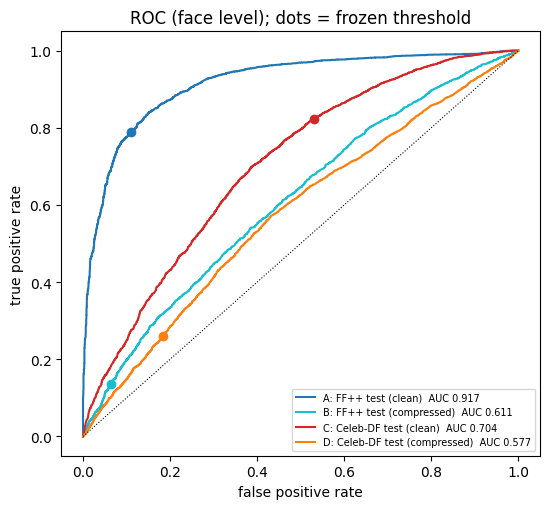

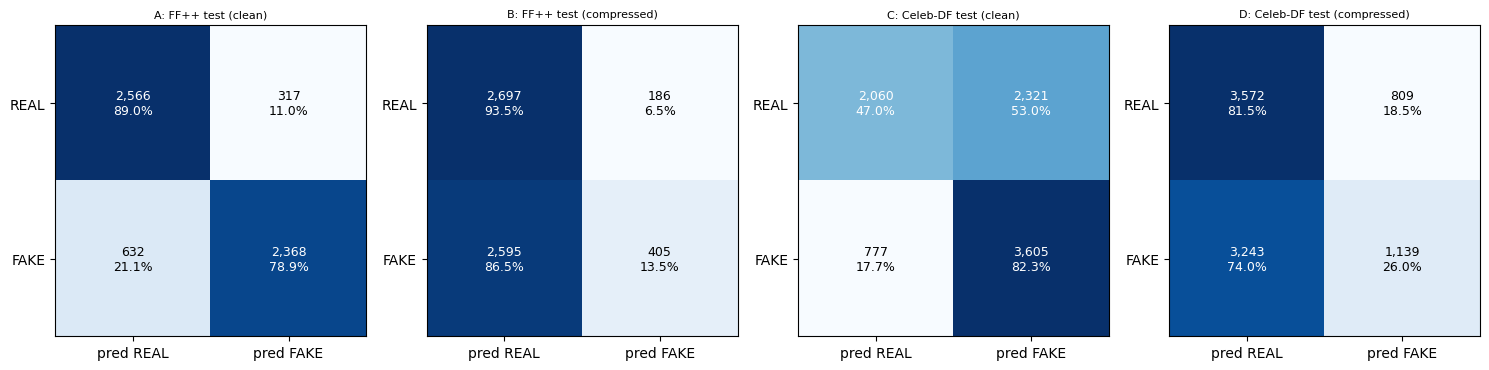

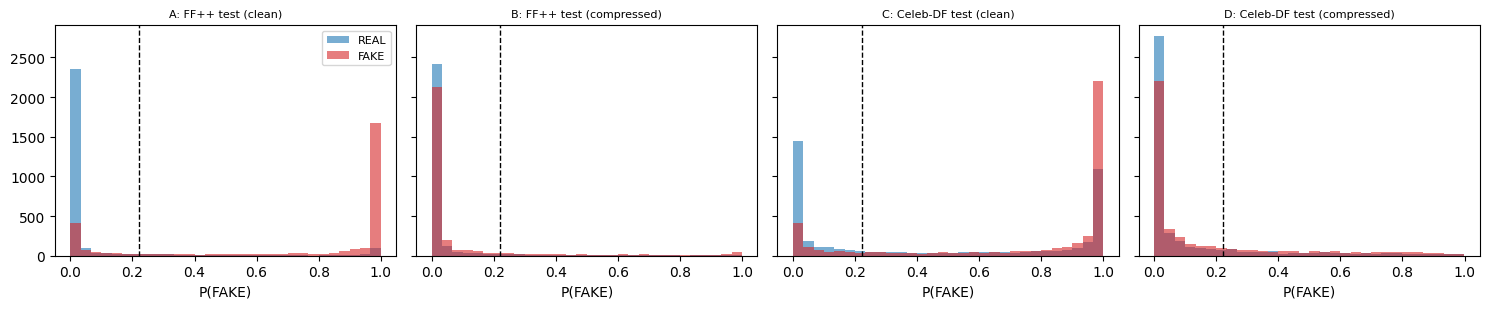

In [7]:
# ============================================================
# PLOTS: ROC, confusion matrices, score distributions
# ============================================================
colors = {"A": "tab:blue", "B": "tab:cyan", "C": "tab:red", "D": "tab:orange"}
fig, ax = plt.subplots(figsize=(5.6, 5.2))
for k in "ABCD":
    f = preds[k]; fpr, tpr, _ = roc_curve(f["label"], f["prob_fake"])
    a = long[(long.cond == k) & (long.level == "face") & (long.metric == "auc")].iloc[0]
    ax.plot(fpr, tpr, c=colors[k], label=f"{cond[k]['name']}  AUC {a.value:.3f}")
    r = long[(long.cond == k) & (long.level == "face") & (long.metric == "recall")].iloc[0].value
    s = long[(long.cond == k) & (long.level == "face") & (long.metric == "specificity")].iloc[0].value
    ax.scatter([1 - s], [r], c=colors[k], s=36, zorder=3)
ax.plot([0, 1], [0, 1], "k:", lw=0.8); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("ROC (face level); dots = frozen threshold"); ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "roc_curves.png"), dpi=130); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, k in zip(axes, "ABCD"):
    g = long[(long.cond == k) & (long.level == "face")].set_index("metric")["value"]
    cm = np.array([[g["tn"], g["fp"]], [g["fn"], g["tp"]]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(cm[i, j]):,}\n{100 * cm[i, j] / cm[i].sum():.1f}%", ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["pred REAL", "pred FAKE"]); ax.set_yticks([0, 1], ["REAL", "FAKE"]); ax.set_title(cond[k]["name"], fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "confusion_matrices.png"), dpi=130); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, k in zip(axes, "ABCD"):
    f = preds[k]
    ax.hist(f.loc[f.label == 0, "prob_fake"], bins=30, alpha=0.6, label="REAL", color="tab:blue")
    ax.hist(f.loc[f.label == 1, "prob_fake"], bins=30, alpha=0.6, label="FAKE", color="tab:red")
    ax.axvline(THRESHOLD, c="k", ls="--", lw=1); ax.set_title(cond[k]["name"], fontsize=8); ax.set_xlabel("P(FAKE)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "score_distributions.png"), dpi=130); plt.show()

In [8]:
# ============================================================
# BASELINE: blur-only classifier on FIXED-SIZE crops (the XceptionNet must beat this)
# Direction fixed in advance from the Step 5 finding: lower sharpness => more likely FAKE.
# ============================================================
import cv2
def blur_fixed(path, size=128):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return np.nan
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return float(cv2.Laplacian(img, cv2.CV_64F).var())

blur_rows = []
if BLUR_BASELINE:
    t0 = time.time()
    for k in "ABCD":
        df = cond[k]["df"]
        sc = np.array([blur_fixed(os.path.join(cond[k]["root"], r)) for r in df["face_rel"]])
        tmp = pd.DataFrame({"face_id": df["face_id"], "video_id": df["video_id"], "label": df["label"], "blur": sc}).dropna()
        auc_f = roc_auc_score(tmp["label"], -tmp["blur"])
        v = tmp.groupby("video_id").agg(label=("label", "first"), blur=("blur", "mean"))
        auc_v = roc_auc_score(v["label"], -v["blur"])
        model_f = long[(long.cond == k) & (long.level == "face") & (long.metric == "auc")].iloc[0]
        model_v = long[(long.cond == k) & (long.level == "video") & (long.metric == "auc")].iloc[0]
        blur_rows.append({"cond": k, "blur_auc_face": round(auc_f, 4), "model_auc_face": round(model_f.value, 4),
                          "blur_auc_video": round(auc_v, 4), "model_auc_video": round(model_v.value, 4),
                          "model_beats_blur": bool(model_f.ci_lo > auc_f)})
    blur_tab = pd.DataFrame(blur_rows); blur_tab.to_csv(os.path.join(OUT, "blur_baseline.csv"), index=False)
    print(f"({time.time() - t0:.0f}s)\n", blur_tab.to_string(index=False))
    print("model_beats_blur = the lower end of the model's 95% CI is above the blur-only AUC.")

(44s)
 cond  blur_auc_face  model_auc_face  blur_auc_video  model_auc_video  model_beats_blur
   A         0.5796          0.9168          0.5820           0.9374              True
   B         0.5681          0.6109          0.5697           0.6021             False
   C         0.6264          0.7045          0.6336           0.7608              True
   D         0.6105          0.5766          0.6196           0.6092             False
model_beats_blur = the lower end of the model's 95% CI is above the blur-only AUC.


In [9]:
# ============================================================
# SAVE RUN METADATA AND PRINT THE SUMMARY
# ============================================================
run_meta = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "model_sha256": sha256(best_pt), "config_sha256": sha256(config_json), "threshold": THRESHOLD, "threshold_method": thr_info["method"],
    "manifest_sha256": meta["manifest_sha256"], "bootstrap": {"reps": BOOT_REPS, "seed": BOOT_SEED, "unit": "video"},
    "conditions": {k: {"faces": int(len(cond[k]["df"])), "videos": int(cond[k]["df"]["video_id"].nunique()), "name": cond[k]["name"]} for k in "ABCD"},
    "best_epoch": config["best_epoch"], "torch": torch.__version__,
    "note": "Threshold frozen on validation. Test splits opened for the first time in this step. Nothing was tuned here.",
}
json.dump(run_meta, open(os.path.join(OUT, "eval_meta.json"), "w"), indent=2)
print("saved:", sorted(os.listdir(OUT)))
print("\nHEADLINE (face level, AUC with 95% CI):")
for k in "ABCD":
    r = long[(long.cond == k) & (long.level == "face") & (long.metric == "auc")].iloc[0]
    print(f"  {cond[k]['name']:34s} {r.value:.3f} [{r.ci_lo:.3f}, {r.ci_hi:.3f}]")
print("\nNext: if D (or B) is near chance, tell me before Step 2.6. Do NOT retrain or change the threshold based on these numbers.")

saved: ['blur_baseline.csv', 'confusion_matrices.png', 'eval_meta.json', 'flip_summary.csv', 'flips_A_B.csv', 'flips_C_D.csv', 'metric_deltas.csv', 'metrics_face.csv', 'metrics_long.csv', 'metrics_video.csv', 'predictions_A.csv', 'predictions_B.csv', 'predictions_C.csv', 'predictions_D.csv', 'roc_curves.png', 'score_distributions.png', 'video_predictions_A.csv', 'video_predictions_B.csv', 'video_predictions_C.csv', 'video_predictions_D.csv']

HEADLINE (face level, AUC with 95% CI):
  A: FF++ test (clean)               0.917 [0.882, 0.946]
  B: FF++ test (compressed)          0.611 [0.556, 0.666]
  C: Celeb-DF test (clean)           0.704 [0.661, 0.746]
  D: Celeb-DF test (compressed)      0.577 [0.532, 0.623]

Next: if D (or B) is near chance, tell me before Step 2.6. Do NOT retrain or change the threshold based on these numbers.
